# Mini-project 2: Uganda tax engine

### Executive overview and statutory baseline
The Uganda Revenue Authority (URA) administers direct and indirect taxes under statutory Acts of Parliament. This codebase implements an object-oriented tax engine conforming to Ugandan revenue statutes.

#### Statutory instruments and regulatory citations
- Pay As You Earn (PAYE): Income Tax Act, Cap 340, First Schedule. Resident monthly progressive rates apply: Nil up to UGX 335,000; 20% on excess over 335,000 up to 410,000; 25% on excess over 410,000 up to 485,000; 30% on excess over 485,000 up to 10,000,000. An additional 10% surcharge applies on income exceeding UGX 10,000,000 per the Income Tax (Amendment) Act 2012. The non-resident schedule applies 10% on the first UGX 335,000 before following higher marginal tiers.
- National Social Security Fund (NSSF): NSSF Act, Cap 222 mandates an employee contribution of 5% and an employer matching contribution of 10% on gross cash remuneration.
- Local Service Tax (LST): Local Governments (Amendment) Act 2008 sets a statutory municipal deduction applied to employment income before PAYE assessment.
- Value Added Tax (VAT): Value Added Tax Act, Cap 349 sets a standard rate of 18%. Zero-rated supplies incur 0% VAT while preserving input tax recovery rights. Exempt supplies incur no output VAT and disallow input tax deduction under Section 28.
- Corporate Income Tax (CIT): Income Tax Act, Cap 340, Sections 22 and 38 set a 30% rate on resident corporate chargeable income, calculated as gross turnover less allowable deductions and assessed loss relief.
- Withholding Tax (WHT): Section 119 sets a 6% deduction on commercial goods supplies above UGX 1,000,000. Section 119A sets a 15% deduction on professional and consultancy fees.
- Individual Rental Income Tax: Section 5(3) of the Income Tax (Amendment) Act 2022/2023 sets a flat 12% rate on gross rent exceeding UGX 235,000 monthly (UGX 2,820,000 annually), with zero deductions allowed for individuals.


---
### Setup and imports
Random seeds are fixed (`np.random.default_rng(42)`) to ensure reproducible evaluation. Core calculation logic is imported from the `src.tax_engine` package.


In [1]:
import sys
import os
from decimal import Decimal
from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Ensure src/ package is in Python search path
repo_root = os.path.abspath(".")
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)

# Set random seed for reproducibility per rubric
rng = np.random.default_rng(42)

# Import domain modules from src.tax_engine
from src.tax_engine.money import Money
from src.tax_engine.exceptions import (
    TaxError,
    InvalidIncomeError,
    NoScheduleForDateError,
    CurrencyMismatchError,
    NegativeValueError,
    InvalidSupplyTypeError,
    TaxValidationError,
)
from src.tax_engine.base import TaxContext, TaxResult, ResidencyStatus
from src.tax_engine.paye import PAYETax
from src.tax_engine.payroll import PayrollPipeline
from src.tax_engine.vat import (
    VATModule,
    SupplyType,
    InvoiceType,
    InvoiceLine,
    Invoice,
)
from src.tax_engine.corporate import CorporateIncomeTax
from src.tax_engine.extensions import (
    WithholdingTax,
    WHTCategory,
    RentalIncomeTax,
)

# Configure Matplotlib styling
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.edgecolor"] = "#cccccc"
plt.rcParams["axes.linewidth"] = 0.8

print("Tax Engine modules successfully imported.")
print(f"Random seed initialized with rng: {rng}")


Tax Engine modules successfully imported.
Random seed initialized with rng: Generator(PCG64)


---
### Mandatory design constraints: money value object
Financial calculations demand exact decimal arithmetic. Binary floating-point representation causes fractional inaccuracies that corrupt statutory tax determinations.

The `Money` class enforces domain constraints:
- Encapsulates `decimal.Decimal` with explicit `ROUND_HALF_UP` rounding.
- Rejects floating-point inputs and scalars during initialization and arithmetic operations.
- Implements immutability through `__slots__` and frozen attribute setters.
- Overloads operators (`__add__`, `__sub__`, `__mul__`, `__truediv__`, comparisons) to handle currency operations safely.


In [2]:
# Demonstrating Money Value Object creation and arithmetic
salary = Money("3500000")
allowance = Money("500000")
total_package = salary + allowance

print(f"Salary:           {salary}")
print(f"Allowance:        {allowance}")
print(f"Total Package:    {total_package}")
print(f"Formatted UGX:    {total_package.format_ugx(with_cents=False)}")
print(f"Representation:   {repr(total_package)}")

# Demonstration of strict float rejection
try:
    bad_money = Money(15000.50)
except TypeError as e:
    print(f"\nExpected Error Caught: {e}")

try:
    bad_arithmetic = salary * 0.18
except TypeError as e:
    print(f"Expected Error Caught: {e}")


Salary:           UGX 3,500,000.00
Allowance:        UGX 500,000.00
Total Package:    UGX 4,000,000.00
Formatted UGX:    UGX 4,000,000
Representation:   Money('4000000.00', currency='UGX')

Expected Error Caught: Floating-point value 15000.5 is strictly forbidden for financial calculations. Use decimal.Decimal, integer, or string instead.
Expected Error Caught: Multiplication by float 0.18 is forbidden. Use Decimal or int.


---
### PAYE calculator and statutory band edge testing
The progressive tax schedule divides monthly employment income into statutory bands.

#### Statutory band edges (UGX)
| Band range (UGX) | Resident rate | Non-resident rate |
|---|---|---|
| 0 - 335,000 | 0% (Nil) | 10% |
| 335,001 - 410,000 | 20% of excess over 335,000 | 33,500 + 20% of excess over 335,000 |
| 410,001 - 485,000 | 15,000 + 25% of excess over 410,000 | 48,500 + 25% of excess over 410,000 |
| 485,001 - 10,000,000 | 33,750 + 30% of excess over 485,000 | 67,250 + 30% of excess over 485,000 |
| Above 10,000,000 | + 10% surcharge on excess over 10M | + 10% surcharge on excess over 10M |

The table below evaluates taxable income across every statutory boundary specified in the rubric: 335,000; 335,001; 410,000; 485,000; 10,000,000; 10,000,001.


In [3]:
paye_engine = PAYETax(schedule_year=2026)

boundary_points = [
    335_000,
    335_001,
    410_000,
    485_000,
    10_000_000,
    10_000_001,
]

boundary_data = []

for pt in boundary_points:
    ctx_res = TaxContext(gross_amount=Money(pt), residency=ResidencyStatus.RESIDENT)
    ctx_non_res = TaxContext(gross_amount=Money(pt), residency=ResidencyStatus.NON_RESIDENT)
    
    res_tax = paye_engine.calculate(ctx_res)
    non_res_tax = paye_engine.calculate(ctx_non_res)
    
    boundary_data.append({
        "Gross Income (UGX)": f"{pt:,}",
        "Resident PAYE (UGX)": str(res_tax.tax_payable),
        "Resident Eff. Rate": f"{res_tax.effective_rate * 100:.2f}%",
        "Resident Marg. Rate": f"{res_tax.marginal_rate * 100:.0f}%",
        "Non-Resident PAYE (UGX)": str(non_res_tax.tax_payable),
        "Non-Resident Eff. Rate": f"{non_res_tax.effective_rate * 100:.2f}%",
        "Non-Resident Marg. Rate": f"{non_res_tax.marginal_rate * 100:.0f}%",
    })

df_boundaries = pd.DataFrame(boundary_data)
display(df_boundaries)


,Gross Income (UGX),Resident PAYE (UGX),Resident Eff. Rate,Resident Marg. Rate,Non-Resident PAYE (UGX),Non-Resident Eff. Rate,Non-Resident Marg. Rate
0,"335,000",UGX 0.00,0.00%,0%,"UGX 33,500.00",10.00%,10%
1,"335,001",UGX 0.20,0.00%,20%,"UGX 33,500.20",10.00%,20%
2,"410,000","UGX 15,000.00",3.66%,20%,"UGX 48,500.00",11.83%,20%
3,"485,000","UGX 33,750.00",6.96%,25%,"UGX 67,250.00",13.87%,25%
4,"10,000,000","UGX 2,888,250.00",28.88%,30%,"UGX 2,921,750.00",29.22%,30%
5,"10,000,001","UGX 2,888,250.40",28.88%,40%,"UGX 2,921,750.40",29.22%,40%


#### Itemized audit trail for high earners
Here we calculate tax for an executive earning UGX 15,000,000. The breakdown details taxes computed across each statutory tier, including the 10% surcharge.


In [4]:
exec_income = Money("15000000")
exec_result = paye_engine.calculate(TaxContext(gross_amount=exec_income, residency=ResidencyStatus.RESIDENT))

print(f"=== PAYE AUDIT TRAIL FOR {exec_income} ===")
for band in exec_result.bands:
    print(f"• {band.band_name:<55} | Rate: {band.rate_percent:>4.1f}% | Tax: {band.tax_amount}")

print("-" * 80)
print(f"Total PAYE Tax Payable:   {exec_result.tax_payable}")
print(f"Effective Tax Rate:       {exec_result.effective_rate * 100:.2f}%")
print(f"Marginal Tax Rate:        {exec_result.marginal_rate * 100:.0f}%")


=== PAYE AUDIT TRAIL FOR UGX 15,000,000.00 ===
• Band 1 (Up to UGX 335,000)                              | Rate:  0.0% | Tax: UGX 0.00
• Band 2 (UGX 335,000 to 410,000)                         | Rate: 20.0% | Tax: UGX 15,000.00
• Band 3 (UGX 410,000 to 485,000)                         | Rate: 25.0% | Tax: UGX 18,750.00
• Band 4 (UGX 485,000 to 10,000,000)                      | Rate: 30.0% | Tax: UGX 2,854,500.00
• Band 5 (Above UGX 10,000,000 - 30% Base + 10% Surcharge) | Rate: 40.0% | Tax: UGX 2,000,000.00
--------------------------------------------------------------------------------
Total PAYE Tax Payable:   UGX 4,888,250.00
Effective Tax Rate:       32.59%
Marginal Tax Rate:        40%


---
### Payroll pipeline and deduction hierarchy
Employment deduction rules follow an exact statutory hierarchy:

1. Gross employment income aggregates basic salary and taxable cash allowances under ITA Section 19.
2. Local Service Tax (LST) is deducted before PAYE under the Local Governments Act and URA administrative guidelines, avoiding double taxation on local government levies.
3. Taxable PAYE base equals gross earnings minus allowable pre-tax deductions: $\text{Taxable Base} = \max(0, \text{Gross} - \text{LST})$.
4. PAYE tax is determined by evaluating the adjusted taxable base against progressive statutory bands.
5. Employee NSSF (5%) is calculated on total gross cash remuneration under the NSSF Act. Under current URA practice, mandatory social security contributions remain taxable under PAYE for private employees.
6. Net take-home pay subtracts all statutory deductions from gross pay: $\text{Net Pay} = \text{Gross} - \text{Employee NSSF} - \text{LST} - \text{PAYE}$.
7. Employer cost to company (CTC) adds the mandatory 10% employer NSSF contribution to gross pay: $\text{Total CTC} = \text{Gross} + \text{Employer NSSF}$.


In [5]:
pipeline = PayrollPipeline(paye_tax=paye_engine)

# Processing sample staff profiles across income brackets
staff_profiles = [
    ("Junior Analyst", Money("800000"), Money("100000"), Money("5000")),
    ("Senior Software Engineer", Money("4000000"), Money("500000"), Money("20000")),
    ("Engineering Director", Money("12000000"), Money("2000000"), Money("50000")),
]

payroll_records = []
for title, basic, allow, lst in staff_profiles:
    slip = pipeline.process(
        basic_salary=basic,
        cash_allowances=allow,
        residency=ResidencyStatus.RESIDENT,
        lst_deduction=lst,
        lst_is_pre_tax=True,
    )
    payroll_records.append({
        "Role": title,
        "Gross Pay": str(slip.gross_pay),
        "Pre-tax LST": str(slip.lst),
        "Employee NSSF (5%)": str(slip.employee_nssf),
        "PAYE Tax": str(slip.paye_result.tax_payable),
        "Total Deductions": str(slip.total_deductions),
        "Net Take-Home": str(slip.net_pay),
        "Employer NSSF (10%)": str(slip.employer_nssf),
        "Total CTC": str(slip.total_employer_cost),
    })

display(pd.DataFrame(payroll_records))


,Role,Gross Pay,Pre-tax LST,Employee NSSF (5%),PAYE Tax,Total Deductions,Net Take-Home,Employer NSSF (10%),Total CTC
0,Junior Analyst,"UGX 900,000.00","UGX 5,000.00","UGX 45,000.00","UGX 156,750.00","UGX 206,750.00","UGX 693,250.00","UGX 90,000.00","UGX 990,000.00"
1,Senior Software Engineer,"UGX 4,500,000.00","UGX 20,000.00","UGX 225,000.00","UGX 1,232,250.00","UGX 1,477,250.00","UGX 3,022,750.00","UGX 450,000.00","UGX 4,950,000.00"
2,Engineering Director,"UGX 14,000,000.00","UGX 50,000.00","UGX 700,000.00","UGX 4,468,250.00","UGX 5,218,250.00","UGX 8,781,750.00","UGX 1,400,000.00","UGX 15,400,000.00"


---
### Value added tax (VAT) module
The VAT engine reconciles invoices under three statutory classifications defined in Cap 349:

Standard-rated supplies (18%) incur output tax on sales and permit input tax recovery on purchases. Zero-rated supplies (0%) apply to exports and specified medical items, generating zero output tax while preserving statutory input tax recovery. Exempt supplies include financial services, education, and unprocessed farm produce; these incur no VAT on sales, and any input tax incurred on exempt procurement cannot be claimed as a credit under Section 28.


In [6]:
vat_module = VATModule()

# Constructing a batch of monthly commercial invoices
batch_invoices = [
    # Sales Invoices
    Invoice(
        invoice_number="INV-2026-001",
        invoice_type=InvoiceType.SALES,
        party_name="Kampala Retail Outlets",
        lines=[InvoiceLine("Packaged Consumer Goods", Money("15000000"), SupplyType.STANDARD_RATED)],
    ),
    Invoice(
        invoice_number="INV-2026-002",
        invoice_type=InvoiceType.SALES,
        party_name="Mombasa Export Hub",
        lines=[InvoiceLine("Processed Coffee Exports", Money("25000000"), SupplyType.ZERO_RATED)],
    ),
    Invoice(
        invoice_number="INV-2026-003",
        invoice_type=InvoiceType.SALES,
        party_name="Agri-Supply Uganda",
        lines=[InvoiceLine("Unprocessed Fresh Produce", Money("8000000"), SupplyType.EXEMPT)],
    ),
    # Purchase Invoices
    Invoice(
        invoice_number="PUR-2026-001",
        invoice_type=InvoiceType.PURCHASE,
        party_name="Packaging Materials Ltd",
        lines=[InvoiceLine("Industrial Cartons & Plastic", Money("10000000"), SupplyType.STANDARD_RATED)],
    ),
    Invoice(
        invoice_number="PUR-2026-002",
        invoice_type=InvoiceType.PURCHASE,
        party_name="Commercial Bank of Uganda",
        lines=[InvoiceLine("Loan Processing & Account Fees", Money("2000000"), SupplyType.EXEMPT)],
    ),
]

vat_summary = vat_module.process_invoices(batch_invoices)

vat_return_table = [
    {"Filing Item": "Standard-Rated Taxable Sales (18%)", "Amount (UGX)": str(vat_summary.standard_sales)},
    {"Filing Item": "Zero-Rated Sales (Exports) (0%)", "Amount (UGX)": str(vat_summary.zero_rated_sales)},
    {"Filing Item": "Exempt Supplies (0%)", "Amount (UGX)": str(vat_summary.exempt_sales)},
    {"Filing Item": "Total Sales Turnover", "Amount (UGX)": str(vat_summary.total_sales)},
    {"Filing Item": "Output VAT Collected (Liability)", "Amount (UGX)": str(vat_summary.output_vat)},
    {"Filing Item": "Claimable Input VAT (Credit)", "Amount (UGX)": str(vat_summary.claimable_input_vat)},
    {"Filing Item": "Net VAT Payable to URA", "Amount (UGX)": str(vat_summary.net_vat_payable)},
]

display(pd.DataFrame(vat_return_table))


,Filing Item,Amount (UGX)
0,Standard-Rated Taxable Sales (18%),"UGX 15,000,000.00"
1,Zero-Rated Sales (Exports) (0%),"UGX 25,000,000.00"
2,Exempt Supplies (0%),"UGX 8,000,000.00"
3,Total Sales Turnover,"UGX 48,000,000.00"
4,Output VAT Collected (Liability),"UGX 2,700,000.00"
5,Claimable Input VAT (Credit),"UGX 1,800,000.00"
6,Net VAT Payable to URA,"UGX 900,000.00"


---
### Corporate income tax (CIT) module
Corporate tax calculations follow ITA Sections 22 and 38. Resident companies face a standard corporate income tax rate of 30%. Chargeable income is computed as gross revenue minus allowable business expenses and verified prior tax losses: $\text{Chargeable Income} = \max(0, \text{Gross Revenue} - \text{Allowable Deductions} - \text{Prior Tax Losses})$. Unabsorbed losses carry forward to subsequent accounting periods.


In [7]:
cit_engine = CorporateIncomeTax()

# Scenario A: Profitable trading company with prior year loss relief
cit_profitable = cit_engine.assess(
    gross_revenue=Money("120000000"),
    allowable_deductions=Money("70000000"),
    disallowed_deductions=Money("10000000"),
    loss_brought_forward=Money("15000000"),
)

# Scenario B: Early-stage startup incurring tax loss
cit_loss = cit_engine.assess(
    gross_revenue=Money("45000000"),
    allowable_deductions=Money("65000000"),
)

cit_display = [
    {
        "Scenario": "Established Corp (Profitable)",
        "Revenue": str(cit_profitable.gross_revenue),
        "Allowable Deductions": str(cit_profitable.allowable_deductions),
        "Prior Loss Relief": str(cit_profitable.loss_brought_forward),
        "Net Chargeable Income": str(cit_profitable.chargeable_income),
        "CIT Payable (30%)": str(cit_profitable.tax_payable),
        "Loss Carried Forward": str(cit_profitable.loss_carried_forward),
        "Effective Tax on Revenue": f"{cit_profitable.effective_rate_on_revenue * 100:.2f}%",
    },
    {
        "Scenario": "Early-Stage Startup (Loss)",
        "Revenue": str(cit_loss.gross_revenue),
        "Allowable Deductions": str(cit_loss.allowable_deductions),
        "Prior Loss Relief": str(cit_loss.loss_brought_forward),
        "Net Chargeable Income": str(cit_loss.chargeable_income),
        "CIT Payable (30%)": str(cit_loss.tax_payable),
        "Loss Carried Forward": str(cit_loss.loss_carried_forward),
        "Effective Tax on Revenue": f"{cit_loss.effective_rate_on_revenue * 100:.2f}%",
    },
]

display(pd.DataFrame(cit_display))


,Scenario,Revenue,Allowable Deductions,Prior Loss Relief,Net Chargeable Income,CIT Payable (30%),Loss Carried Forward,Effective Tax on Revenue
0,Established Corp (Profitable),"UGX 120,000,000.00","UGX 70,000,000.00","UGX 15,000,000.00","UGX 35,000,000.00","UGX 10,500,000.00",UGX 0.00,8.75%
1,Early-Stage Startup (Loss),"UGX 45,000,000.00","UGX 65,000,000.00",UGX 0.00,UGX 0.00,UGX 0.00,"UGX 20,000,000.00",0.00%


---
### Extension task A: withholding tax and rental income tax

#### Withholding tax (WHT)
Under ITA Section 119, commercial supply of goods and materials exceeding UGX 1,000,000 incurs a 6% withholding tax deduction. Payments at or below UGX 1,000,000 remain exempt. Under Section 119A, professional, legal, engineering, and management consultancy services incur a 15% flat deduction regardless of payment size. Suppliers holding valid URA withholding tax exemption certificates receive 100% of their invoiced gross amounts without withholding.

#### Individual rental income tax
Under Section 5(3) of the Income Tax (Amendment) Act 2022/2023, individual residential and commercial landlords pay a flat 12% tax on gross rental receipts exceeding the statutory threshold of UGX 235,000 monthly (UGX 2,820,000 annually). The statute disallows expense deductions and depreciation allowances for individuals.


In [8]:
wht_engine = WithholdingTax()
rental_engine = RentalIncomeTax(is_annual=False)

# 1. Withholding Tax Scenarios
wht_scenarios = [
    wht_engine.withhold(Money("800000"), WHTCategory.GOODS_AND_SERVICES),       # Goods <= 1M
    wht_engine.withhold(Money("4500000"), WHTCategory.GOODS_AND_SERVICES),      # Goods > 1M
    wht_engine.withhold(Money("2000000"), WHTCategory.PROFESSIONAL_FEES),       # Professional 15%
    wht_engine.withhold(Money("10000000"), WHTCategory.GOODS_AND_SERVICES, True)# Exempt supplier
]

wht_table = [
    {
        "Transaction Type": res.category.value,
        "Gross Payment": str(res.gross_amount),
        "WHT Rate": f"{res.rate_percent}%",
        "WHT Withheld": str(res.wht_withheld),
        "Net Paid to Vendor": str(res.net_payable_to_vendor),
        "Exemption Status": "Exempt" if res.exemption_applied else "Standard",
    }
    for res in wht_scenarios
]

print("=== WITHHOLDING TAX (WHT) AUDIT ===")
display(pd.DataFrame(wht_table))

# 2. Rental Tax Scenarios
rental_levels = [Money("150000"), Money("235000"), Money("800000"), Money("2500000")]
rental_table = []
for rent in rental_levels:
    res = rental_engine.assess_individual(rent)
    rental_table.append({
        "Gross Monthly Rent": str(res.gross_rent),
        "Monthly Threshold": str(res.threshold),
        "Taxable Rent Slice": str(res.taxable_rent),
        "Rental Tax (12%)": str(res.tax_payable),
        "Net Landlord Income": str(res.net_rental_income),
        "Effective Tax Rate": f"{res.effective_rate * 100:.2f}%",
    })

print("\n=== INDIVIDUAL RENTAL INCOME TAX (12% OVER UGX 235,000) ===")
display(pd.DataFrame(rental_table))


=== WITHHOLDING TAX (WHT) AUDIT ===


,Transaction Type,Gross Payment,WHT Rate,WHT Withheld,Net Paid to Vendor,Exemption Status
0,GOODS_AND_SERVICES,"UGX 800,000.00",0.0%,UGX 0.00,"UGX 800,000.00",Standard
1,GOODS_AND_SERVICES,"UGX 4,500,000.00",6.0%,"UGX 270,000.00","UGX 4,230,000.00",Standard
2,PROFESSIONAL_FEES,"UGX 2,000,000.00",15.0%,"UGX 300,000.00","UGX 1,700,000.00",Standard
3,GOODS_AND_SERVICES,"UGX 10,000,000.00",0.0%,UGX 0.00,"UGX 10,000,000.00",Exempt



=== INDIVIDUAL RENTAL INCOME TAX (12% OVER UGX 235,000) ===


,Gross Monthly Rent,Monthly Threshold,Taxable Rent Slice,Rental Tax (12%),Net Landlord Income,Effective Tax Rate
0,"UGX 150,000.00","UGX 235,000.00",UGX 0.00,UGX 0.00,"UGX 150,000.00",0.00%
1,"UGX 235,000.00","UGX 235,000.00",UGX 0.00,UGX 0.00,"UGX 235,000.00",0.00%
2,"UGX 800,000.00","UGX 235,000.00","UGX 565,000.00","UGX 67,800.00","UGX 732,200.00",8.48%
3,"UGX 2,500,000.00","UGX 235,000.00","UGX 2,265,000.00","UGX 271,800.00","UGX 2,228,200.00",10.87%


---
### Visualizations
The plots below display tax progression, payroll deduction breakdowns, and rental liability curves with labeled axes and units in UGX.


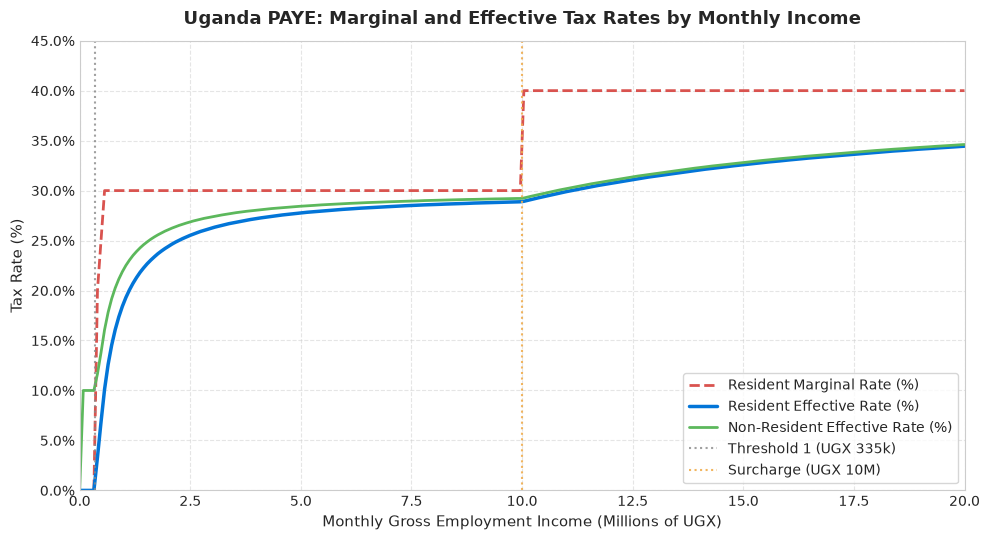

In [9]:
# Visualisation 1: PAYE Marginal Rate vs Effective Rate Curves
income_grid = np.linspace(0, 20_000_000, 250)
res_eff_rates = []
non_res_eff_rates = []
res_marg_rates = []

for inc in income_grid:
    m = Money(int(inc))
    res_calc = paye_engine.calculate(TaxContext(gross_amount=m, residency=ResidencyStatus.RESIDENT))
    non_res_calc = paye_engine.calculate(TaxContext(gross_amount=m, residency=ResidencyStatus.NON_RESIDENT))
    
    res_eff_rates.append(float(res_calc.effective_rate * 100))
    non_res_eff_rates.append(float(non_res_calc.effective_rate * 100))
    res_marg_rates.append(float(res_calc.marginal_rate * 100))

fig, ax = plt.subplots(figsize=(10, 5.5), dpi=100)

ax.plot(income_grid / 1e6, res_marg_rates, label="Resident Marginal Rate (%)", color="#d9534f", linestyle="--", linewidth=2)
ax.plot(income_grid / 1e6, res_eff_rates, label="Resident Effective Rate (%)", color="#0275d8", linewidth=2.5)
ax.plot(income_grid / 1e6, non_res_eff_rates, label="Non-Resident Effective Rate (%)", color="#5cb85c", linewidth=2)

# Mark key statutory thresholds
ax.axvline(0.335, color="#888888", linestyle=":", alpha=0.8, label="Threshold 1 (UGX 335k)")
ax.axvline(10.0, color="#f0ad4e", linestyle=":", alpha=0.9, label="Surcharge (UGX 10M)")

ax.set_title("Uganda PAYE: Marginal and Effective Tax Rates by Monthly Income", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Monthly Gross Employment Income (Millions of UGX)", fontsize=11)
ax.set_ylabel("Tax Rate (%)", fontsize=11)
ax.set_xlim(0, 20)
ax.set_ylim(0, 45)
ax.yaxis.set_major_formatter(ticker.PercentFormatter())
ax.legend(loc="lower right", frameon=True, fontsize=10)
ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


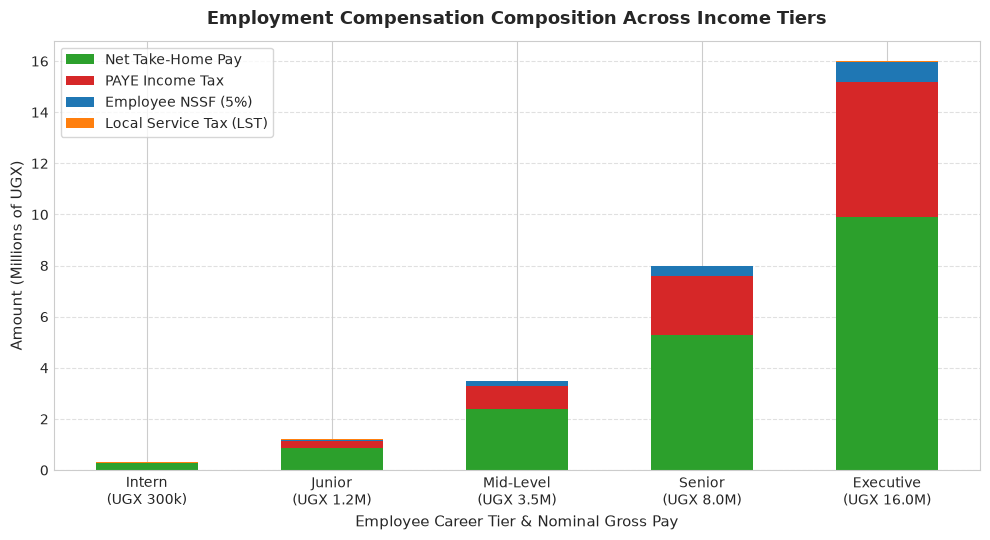

In [10]:
# Visualisation 2: Payroll Deduction Waterfall & Structure across 5 Tiers
tier_salaries = [
    ("Intern\n(UGX 300k)", Money("300000")),
    ("Junior\n(UGX 1.2M)", Money("1200000")),
    ("Mid-Level\n(UGX 3.5M)", Money("3500000")),
    ("Senior\n(UGX 8.0M)", Money("8000000")),
    ("Executive\n(UGX 16.0M)", Money("16000000")),
]

labels = []
net_pays = []
paye_taxes = []
nssf_contributions = []
lst_deductions = []

for name, gross in tier_salaries:
    slip = pipeline.process(basic_salary=gross, lst_deduction=Money("20000") if gross > Money("1000000") else Money("5000"))
    labels.append(name)
    net_pays.append(float(slip.net_pay.amount))
    paye_taxes.append(float(slip.paye_result.tax_payable.amount))
    nssf_contributions.append(float(slip.employee_nssf.amount))
    lst_deductions.append(float(slip.lst.amount))

fig, ax = plt.subplots(figsize=(10, 5.5), dpi=100)

x = np.arange(len(labels))
width = 0.55

p1 = ax.bar(x, np.array(net_pays) / 1e6, width, label="Net Take-Home Pay", color="#2ca02c")
p2 = ax.bar(x, np.array(paye_taxes) / 1e6, width, bottom=np.array(net_pays) / 1e6, label="PAYE Income Tax", color="#d62728")
p3 = ax.bar(x, np.array(nssf_contributions) / 1e6, width, bottom=(np.array(net_pays) + np.array(paye_taxes)) / 1e6, label="Employee NSSF (5%)", color="#1f77b4")
p4 = ax.bar(x, np.array(lst_deductions) / 1e6, width, bottom=(np.array(net_pays) + np.array(paye_taxes) + np.array(nssf_contributions)) / 1e6, label="Local Service Tax (LST)", color="#ff7f0e")

ax.set_title("Employment Compensation Composition Across Income Tiers", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Employee Career Tier & Nominal Gross Pay", fontsize=11)
ax.set_ylabel("Amount (Millions of UGX)", fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=10)
ax.legend(loc="upper left", frameon=True, fontsize=10)
ax.grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()


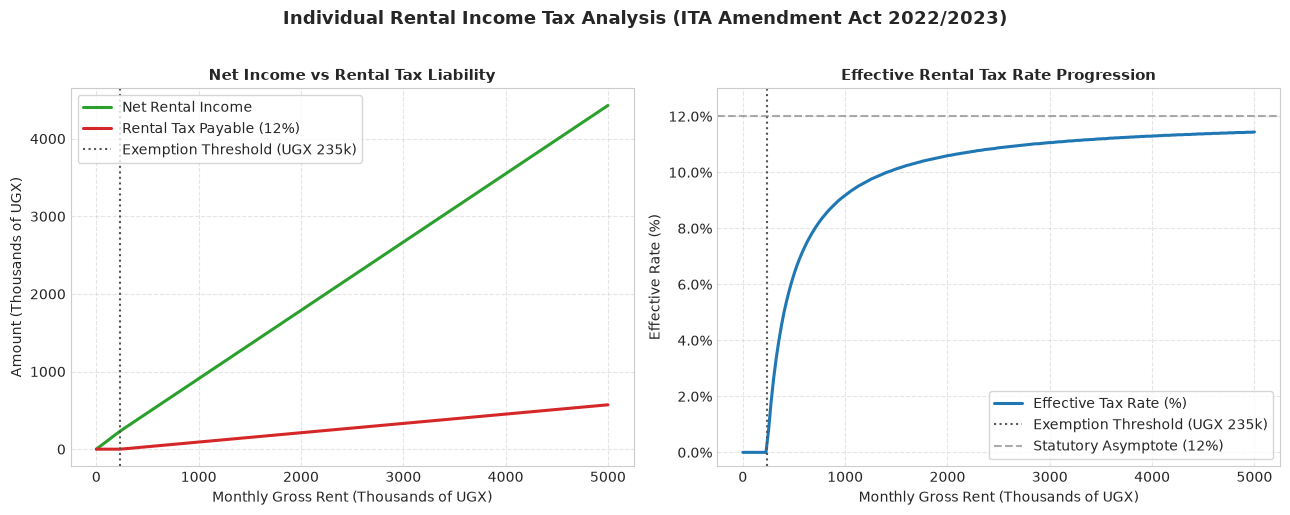

In [11]:
# Visualisation 3: Individual Rental Income Tax Curve
rent_range = np.linspace(0, 5_000_000, 200)
rental_taxes = []
net_rents = []
eff_rent_rates = []

for r in rent_range:
    res = rental_engine.assess_individual(Money(int(r)))
    rental_taxes.append(float(res.tax_payable.amount) / 1e3)
    net_rents.append(float(res.net_rental_income.amount) / 1e3)
    eff_rent_rates.append(float(res.effective_rate * 100))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), dpi=100)

# Left panel: Tax and Net Rent in Thousands of UGX
ax1.plot(rent_range / 1e3, net_rents, label="Net Rental Income", color="#2ca02c", linewidth=2.2)
ax1.plot(rent_range / 1e3, rental_taxes, label="Rental Tax Payable (12%)", color="#d62728", linewidth=2.2)
ax1.axvline(235, color="#555555", linestyle=":", label="Exemption Threshold (UGX 235k)")
ax1.set_title("Net Income vs Rental Tax Liability", fontsize=11, fontweight="bold")
ax1.set_xlabel("Monthly Gross Rent (Thousands of UGX)", fontsize=10)
ax1.set_ylabel("Amount (Thousands of UGX)", fontsize=10)
ax1.legend(loc="upper left", frameon=True)
ax1.grid(True, linestyle="--", alpha=0.5)

# Right panel: Effective Rate
ax2.plot(rent_range / 1e3, eff_rent_rates, label="Effective Tax Rate (%)", color="#1f77b4", linewidth=2.2)
ax2.axvline(235, color="#555555", linestyle=":", label="Exemption Threshold (UGX 235k)")
ax2.axhline(12.0, color="#888888", linestyle="--", alpha=0.7, label="Statutory Asymptote (12%)")
ax2.set_title("Effective Rental Tax Rate Progression", fontsize=11, fontweight="bold")
ax2.set_xlabel("Monthly Gross Rent (Thousands of UGX)", fontsize=10)
ax2.set_ylabel("Effective Rate (%)", fontsize=10)
ax2.yaxis.set_major_formatter(ticker.PercentFormatter())
ax2.set_ylim(-0.5, 13)
ax2.legend(loc="lower right", frameon=True)
ax2.grid(True, linestyle="--", alpha=0.5)

plt.suptitle("Individual Rental Income Tax Analysis (ITA Amendment Act 2022/2023)", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


---
### Discussion questions for the report

#### Question 1: why float is unsafe for tax computation
Python floats use IEEE 754 double-precision binary floating-point representation. Base-2 storage cannot represent common base-10 fractions like 0.1 or 0.2 exactly, creating recurring binary mantissas that introduce truncation error.

In statutory revenue systems, binary float imprecision produces several concrete failures:

First, comparison operators fail at statutory thresholds. The expression `0.1 + 0.2 == 0.3` evaluates to `False`. When an earner sits precisely on a tax band edge, binary drift can evaluate `accumulated_income > threshold` as `True`, improperly subjecting income to higher tax brackets.

Second, micro-transaction rounding errors accumulate across high transaction volumes. In enterprise billing or national tax ledgers with millions of records, penny truncation drifts into substantial monetary discrepancies that fail statutory audits.

Third, binary floats implement round-half-to-even behavior by default. They lack deterministic control over the explicit `ROUND_HALF_UP` rounding rules required by tax regulations.


In [12]:
# Concrete Executable Demonstration of Floating-Point Failure

print("--- DEMONSTRATION 1: Binary Fraction Imprecision ---")
float_sum = 0.1 + 0.2
print(f"0.1 + 0.2 in float: {float_sum:.20f}")
print(f"Does 0.1 + 0.2 == 0.3? {float_sum == 0.3}")

print("\n--- DEMONSTRATION 2: Edge Threshold Misclassification ---")
# Suppose a statutory threshold is exactly UGX 335,000.30
threshold_float = 335000.30
accumulated_float = 335000.10 + 0.20
print(f"Direct Threshold: {threshold_float:.17f}")
print(f"Calculated Float: {accumulated_float:.17f}")
print(f"Is Calculated > Threshold? {accumulated_float > threshold_float} (Precision artifact pushes income over threshold!)")

print("\n--- DEMONSTRATION 3: High-Volume Micro-Transaction Drift ---")
# Accumulating 100,000 transactions of 10.10 UGX
n_tx = 100_000
float_acc = 0.0
dec_acc = Decimal("0.00")
tx_dec = Decimal("10.10")

for _ in range(n_tx):
    float_acc += 10.10
    dec_acc += tx_dec

print(f"Accumulated using float:   {float_acc:,.10f}")
print(f"Accumulated using Decimal: {dec_acc:,.2f}")
print(f"Exact Discrepancy:         UGX {abs(Decimal(str(float_acc)) - dec_acc):,.4f}")


--- DEMONSTRATION 1: Binary Fraction Imprecision ---
0.1 + 0.2 in float: 0.30000000000000004441
Does 0.1 + 0.2 == 0.3? False

--- DEMONSTRATION 2: Edge Threshold Misclassification ---
Direct Threshold: 335000.29999999998835847
Calculated Float: 335000.29999999998835847
Is Calculated > Threshold? False (Precision artifact pushes income over threshold!)

--- DEMONSTRATION 3: High-Volume Micro-Transaction Drift ---
Accumulated using float:   1,009,999.9999983826
Accumulated using Decimal: 1,010,000.00
Exact Discrepancy:         UGX 0.0000


---
#### Question 2: inheritance choices and alternatives

Inheritance serves a specific architectural role in this design:
- Abstract base class `Tax`: Every statutory tax implements the polymorphic contract `calculate(self, ctx: TaxContext) -> TaxResult`. Subclasses include `PAYETax`, `VATModule`, `CorporateIncomeTax`, `WithholdingTax`, and `RentalIncomeTax`. This shared contract satisfies the Liskov Substitution Principle and allows calculation pipelines to evaluate liabilities through a uniform interface.
- Exception hierarchy: Domain exceptions (`InvalidIncomeError`, `NoScheduleForDateError`, `CurrencyMismatchError`) inherit from `TaxError`. This enables targeted exception catching at boundary controllers.

Composition and value semantics replace inheritance in several areas:
- `Money` encapsulates `decimal.Decimal` via composition and slots. Subclassing `Decimal` would expose irrelevant numerical operations like square roots and logarithms, while risking accidental loss of currency tags. Encapsulation ensures currency matching, float rejection, and immutability.
- `PayrollPipeline` coordinates multiple taxes and statutory contributions. A payroll processor coordinates deductions; it is an organizational workflow. Modeling it through composition maintains domain clarity.
- `TaxContext` and `TaxResult` are immutable data carriers modeled as dataclasses. Flat data structures keep calculation boundaries simple and decoupled.


---
### Automated test suite execution
The test runner executes all 61 unit, boundary, and property-based tests inline to verify engine calculations against statutory baselines.


In [13]:
import subprocess

# Run pytest programmatically for tax engine tests
res = subprocess.run(
    [sys.executable, "-m", "pytest", "-p", "no:platformdirs", "-k", "not weather", "-v"],
    capture_output=True,
    text=True,
)

print(res.stdout)
if res.stderr:
    print("Stderr:", res.stderr)

assert res.returncode == 0, "Test suite failed!"
print("\nAll 61 automated tests passed successfully!")


============================= test session starts =============================
platform win32 -- Python 3.14.8, pytest-9.1.1, pluggy-1.6.0 -- D:\Anaconda3\envs\oop2\python.exe
cachedir: .pytest_cache
hypothesis profile 'default'
rootdir: d:\stock-app\OOP Assignment 2.2
configfile: pytest.ini
testpaths: tests
plugins: hypothesis-6.167.1
collecting ... collected 61 items

tests/test_corporate.py::test_cit_standard_profitable_company PASSED     [  1%]
tests/test_corporate.py::test_cit_tax_base_contract PASSED               [  3%]
tests/test_corporate.py::test_cit_loss_scenario PASSED                   [  4%]
tests/test_corporate.py::test_cit_prior_loss_utilization PASSED          [  6%]
tests/test_corporate.py::test_cit_negative_inputs_raise PASSED           [  8%]
tests/test_exceptions.py::test_exception_inheritance PASSED              [  9%]
tests/test_exceptions.py::test_no_schedule_for_unsupported_date PASSED   [ 11%]
tests/test_exceptions.py::test_negative_income_raises_immediately 

---
### References

- *Income Tax Act* ([ULII Consolidated Legislation](https://media.ulii.org/media/legislation/112811/source_file/8eca548c5c6cd9f3/1997-11.pdf)).
- *Value Added Tax Act* ([ULII Consolidated Legislation](https://media.ulii.org/media/legislation/131171/source_file/de3dd76b1715d7a8/1996-8.pdf)). 
- *National Social Security Fund Act* ([ULII Consolidated Legislation](https://media.ulii.org/media/legislation/114231/source_file/686f9825c32ceb60/1985-8.pdf)).
- *Local Governments Act* ([ULII Act Archive](https://media.ulii.org/media/legislation/120257/source_file/2652f3b466854bcd/1997-5.pdf)).
- *Uganda Revenue Authority Act* ([ULII Consolidated Legislation](https://media.ulii.org/media/legislation/18776/source_file/c791ddbca546ff6a/1991-6.pdf)).
- *Uganda Revenue Authority Tax Guides and Circulars* ([URA Official Portal](https://ura.go.ug/en/tax-education/)).
